# Crash Media - Photos and Movies

Crash tests are documented not only by measured channels but also by photos and high-speed movies. In this notebook we'll show you how to list these files for a crash test stored in an ASAM ODS server and how to display them directly in the notebook.

In the ASAM ODS model, files are represented by instances of the base element `AoFile`. In this data model the application element is `MeaResultFile`, whose `FileParent` relation points to the `MeaResult` (`AoMeasurement`) it belongs to. Photos and movies are attached to the measurements named `PHOTO` and `MOVIE` of a test.

## Dependencies for this notebook

💡The [ASAM ODSBox](https://pypi.org/project/odsbox/) contains some functionality that wraps the ODS HTTP API making using Python easier.

In [1]:
try:
  import odsbox
except ImportError:
  %pip install odsbox


import os
import shutil
import subprocess
import tempfile

from IPython.display import display, Image, Video, FileLink, Markdown
from PIL import Image as PILImage

import odsbox.proto.ods_pb2 as ods
from odsbox.con_i import ConI

### Establish session

The ODS HTTP API is a session based API. The session ID is called con_i in the ODS documentation. The [ASAM ODSBox](https://pypi.org/project/odsbox/) uses con_i as API object representing the session. Close this session to release the connection license. Otherwise the session will be auto closed after 30 minutes of inactivity.

In [2]:

con_i = ConI(url='https://tdm183759.peak-applications.com:443/api', auth=('user','welcome'), verify_certificate=False, allow_redirects=True)
NHTSA_Test_No = "15497"


c:\Peak\github\data_management_learning_path\.venv\Lib\site-packages\urllib3\connectionpool.py:1099: InsecureRequestWarning: Unverified HTTPS request is being made to host 'tdm183759.peak-applications.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\Peak\github\data_management_learning_path\.venv\Lib\site-packages\urllib3\connectionpool.py:1099: InsecureRequestWarning: Unverified HTTPS request is being made to host 'tdm183759.peak-applications.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


### Find and download media files

`list_media_files` queries all `MeaResultFile` instances attached to the measurement with the given name of our test, sorted by id. Index files with the extensions `mii` (movie index) and `pho` (photo index) are excluded.

`download_file` uses the ODS `file-access` method to fetch the content of an `AoFile` instance, identified by application element id (aid) and instance id (iid), into a local temporary folder.

In [3]:
EXCLUDED_EXTENSIONS = {"mii", "pho"}
download_dir = tempfile.mkdtemp(prefix="ods_media_")

mea_result_file_aid = con_i.mc.entity("MeaResultFile").aid


def list_media_files(mea_result_name):
    files = con_i.query_data({
        "MeaResultFile": {
            "FileParent.test.name": NHTSA_Test_No,
            "FileParent.name": mea_result_name
        },
        "$attributes": {
            "Id": 1,
            "Name": 1,
            "OriginalFileName": 1,
            "FileMimeType": 1,
            "Size": 1
        },
        "$orderby": {
        "Id": 1
        }
    })
    if files.empty:
        return files

    file_names = files["MeaResultFile.OriginalFileName"].fillna("")
    file_names = file_names.where(file_names != "", files["MeaResultFile.Name"])
    extensions = file_names.str.rsplit(".", n=1).str[-1].str.lower()
    return files[~extensions.isin(EXCLUDED_EXTENSIONS)].reset_index(drop=True)


def download_file(file_id):
    target_folder = os.path.join(download_dir, str(file_id))
    os.makedirs(target_folder, exist_ok=True)
    return con_i.file_access_download(
        ods.FileIdentifier(aid=mea_result_file_aid, iid=int(file_id)),
        target_folder,
        overwrite_existing=True)

## Photos

### List photo files

In [4]:
photos = list_media_files("PHOTO")
print(f"{len(photos)} photo file(s) found for test {NHTSA_Test_No}")
photos

c:\Peak\github\data_management_learning_path\.venv\Lib\site-packages\urllib3\connectionpool.py:1099: InsecureRequestWarning: Unverified HTTPS request is being made to host 'tdm183759.peak-applications.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


20 photo file(s) found for test 15497


,MeaResultFile.Id,MeaResultFile.Name,MeaResultFile.OriginalFileName,MeaResultFile.FileMimeType,MeaResultFile.Size
0,2217,v15497P018.JPG,v15497P018.JPG,image/jpeg,3193508
1,2218,v15497P019.JPG,v15497P019.JPG,image/jpeg,2751855
2,2219,v15497P016.JPG,v15497P016.JPG,image/jpeg,1442450
3,2220,v15497P010.JPG,v15497P010.JPG,image/jpeg,1705814
4,2221,v15497P017.JPG,v15497P017.JPG,image/jpeg,1583320
5,2222,v15497P005.JPG,v15497P005.JPG,image/jpeg,2149058
6,2223,v15497P013.JPG,v15497P013.JPG,image/jpeg,1458216
7,2224,v15497P004.JPG,v15497P004.JPG,image/jpeg,1886364
8,2226,v15497P006.JPG,v15497P006.JPG,image/jpeg,2008207
9,2227,v15497P012.JPG,v15497P012.JPG,image/jpeg,1478610


### Display the first photo

Common web formats (JPEG, PNG, GIF) are displayed directly, all other formats are rendered using Pillow.

c:\Peak\github\data_management_learning_path\.venv\Lib\site-packages\urllib3\connectionpool.py:1099: InsecureRequestWarning: Unverified HTTPS request is being made to host 'tdm183759.peak-applications.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\Peak\github\data_management_learning_path\.venv\Lib\site-packages\urllib3\connectionpool.py:1099: InsecureRequestWarning: Unverified HTTPS request is being made to host 'tdm183759.peak-applications.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


**v15497P018.JPG** (Id 2217)

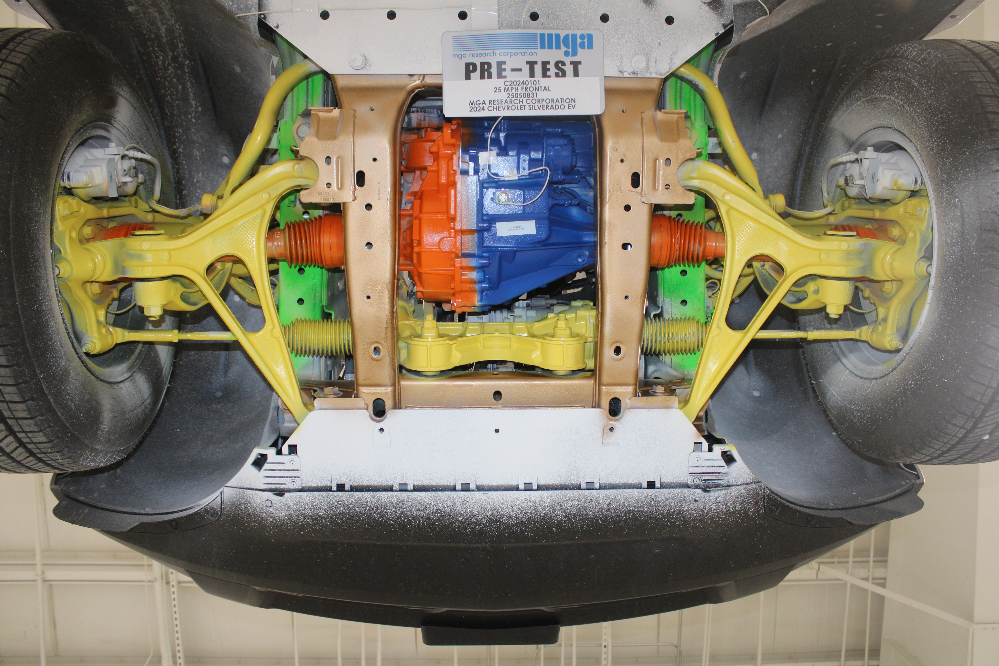

In [5]:
WEB_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".gif"}

if photos.empty:
    print("No photos available.")
else:
    photo = photos.iloc[0]
    photo_path = download_file(photo["MeaResultFile.Id"])
    display(Markdown(f"**{photo['MeaResultFile.Name']}** (Id {photo['MeaResultFile.Id']})"))

    if os.path.splitext(photo_path)[1].lower() in WEB_IMAGE_EXTENSIONS:
        display(Image(filename=photo_path, width=800))
    else:
        img = PILImage.open(photo_path)
        img.thumbnail((800, 800))
        display(img)

## Movies

### List movie files

In [6]:
movies = list_media_files("MOVIE")
print(f"{len(movies)} movie file(s) found for test {NHTSA_Test_No}")
movies

10 movie file(s) found for test 15497


c:\Peak\github\data_management_learning_path\.venv\Lib\site-packages\urllib3\connectionpool.py:1099: InsecureRequestWarning: Unverified HTTPS request is being made to host 'tdm183759.peak-applications.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


,MeaResultFile.Id,MeaResultFile.Name,MeaResultFile.OriginalFileName,MeaResultFile.FileMimeType,MeaResultFile.Size
0,2238,v15497C005.mp4,v15497C005.mp4,video/mp4,34975351
1,2239,v15497C007.mp4,v15497C007.mp4,video/mp4,36522444
2,2240,v15497C004.mp4,v15497C004.mp4,video/mp4,5653192
3,2242,v15497C006.mp4,v15497C006.mp4,video/mp4,35518569
4,2243,v15497C010.mp4,v15497C010.mp4,video/mp4,35609245
5,2244,v15497C001.mp4,v15497C001.mp4,video/mp4,35132105
6,2245,v15497C008.mp4,v15497C008.mp4,video/mp4,35468362
7,2246,v15497C003.mp4,v15497C003.mp4,video/mp4,9901872
8,2247,v15497C009.mp4,v15497C009.mp4,video/mp4,34836791
9,2248,v15497C002.mp4,v15497C002.mp4,video/mp4,34651762


### Play the first movie

The movie is embedded into the notebook and presented in an HTML5 video player. Browsers can only play some container formats (MP4, WebM, Ogg). Other formats (e.g. AVI, WMV, MPG) are converted to MP4 if `ffmpeg` is available; otherwise a download link is shown.

👉 Embedding large movies increases the size of the notebook considerably.

In [7]:
BROWSER_VIDEO_TYPES = {".mp4": "video/mp4", ".webm": "video/webm", ".ogg": "video/ogg", ".ogv": "video/ogg"}


def to_mp4(source_path):
    ffmpeg = shutil.which("ffmpeg")
    if ffmpeg is None:
        return None
    target_path = os.path.splitext(source_path)[0] + ".mp4"
    subprocess.run(
        [ffmpeg, "-y", "-loglevel", "error", "-i", source_path,
         "-c:v", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", target_path],
        check=True)
    return target_path


if movies.empty:
    print("No movies available.")
else:
    movie = movies.iloc[0]
    movie_path = download_file(movie["MeaResultFile.Id"])
    display(Markdown(f"**{movie['MeaResultFile.Name']}** (Id {movie['MeaResultFile.Id']})"))

    extension = os.path.splitext(movie_path)[1].lower()
    if extension not in BROWSER_VIDEO_TYPES:
        converted_path = to_mp4(movie_path)
        if converted_path is not None:
            movie_path, extension = converted_path, ".mp4"

    if extension in BROWSER_VIDEO_TYPES:
        display(Video(movie_path, embed=True, mimetype=BROWSER_VIDEO_TYPES[extension], width=800,
                      html_attributes="controls loop"))
    else:
        print(f"Format '{extension}' cannot be played in the browser and ffmpeg is not available for conversion.")
        display(FileLink(os.path.relpath(movie_path)))

c:\Peak\github\data_management_learning_path\.venv\Lib\site-packages\urllib3\connectionpool.py:1099: InsecureRequestWarning: Unverified HTTPS request is being made to host 'tdm183759.peak-applications.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\Peak\github\data_management_learning_path\.venv\Lib\site-packages\urllib3\connectionpool.py:1099: InsecureRequestWarning: Unverified HTTPS request is being made to host 'tdm183759.peak-applications.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


**v15497C005.mp4** (Id 2238)

## Close session
Don't forget to close the session to release the connection license. Otherwise the session will be auto closed after 30 minutes of inactivity.

In [8]:
con_i.logout()
shutil.rmtree(download_dir, ignore_errors=True)

c:\Peak\github\data_management_learning_path\.venv\Lib\site-packages\urllib3\connectionpool.py:1099: InsecureRequestWarning: Unverified HTTPS request is being made to host 'tdm183759.peak-applications.com'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


## License

Copyright © 2026 [Peak Solution GmbH](https://peak-solution.de)

The training material in this repository is licensed under a Creative Commons BY-NC-SA 4.0 license. See [LICENSE](../LICENSE) file for more information.

**Notebook**: [📓 Back to ASAM ODS Overview](overview.ipynb)